# External Validation on PhysioNet

## 0. Paths and settings

In [49]:
from pathlib import Path

# >>> Change these two paths to the folders on your computer. <<<
WESAD_OUTPUT_DIR = Path("/Users/chengxuning/Data Science/WESAD_wearable_stress/classification_calibrated_2min.csv")
PHYSIONET_STRESS_DIR = Path("/Users/chengxuning/Data Science/WESAD_wearable_stress/data/Wearable_Dataset/STRESS")

OUTPUT_DIR = Path("outputs_external")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_SECONDS = 60
CALIBRATION_WINDOWS = 2  # two minutes, the same as the WESAD main analysis

# Subjects excluded because of problems listed by the dataset authors.
EXCLUDED_SUBJECTS = {
    "S02": "duplicated data",
    "f07": "wristband cover not removed; signals not valid",
    "f14_a": "recording split into two parts",
    "f14_b": "recording split into two parts",
}

# Extra button presses to drop, by subject.
# Tag numbers are 1-based, counted in the order they appear in tags.csv.
# Add a subject here only after checking its tags by eye.
TAG_DROP = {}

for path in [WESAD_OUTPUT_DIR, PHYSIONET_STRESS_DIR]:
    if not path.exists():
        print(f"Folder not found, please edit the path: {path}")

V2_BASELINE_SECONDS = 180  # V2: use only the last 3 minutes before tag 1

## 1. Feature functions copied from `file1.ipynb`

In [50]:
# %pip install neurokit2   # run once if neurokit2 is not installed

import numpy as np
import pandas as pd
import neurokit2 as nk
from scipy.signal import butter, sosfiltfilt

In [51]:
def extract_basic_features(values, fs, prefix):
    """Extract five descriptive features from a one-dimensional signal."""
    values = np.asarray(values, dtype=float).reshape(-1)

    feature_names = [
        f"{prefix}_mean",
        f"{prefix}_std",
        f"{prefix}_min",
        f"{prefix}_max",
        f"{prefix}_slope",
    ]

    # Do not silently remove samples or change their time positions.
    if len(values) < 2 or not np.isfinite(values).all():
        return {name: np.nan for name in feature_names}

    time_s = np.arange(len(values)) / fs

    # Least-squares slope with time measured in seconds.
    centered_time = time_s - time_s.mean()
    slope = np.sum(
        centered_time * (values - values.mean())
    ) / np.sum(centered_time ** 2)

    return {
        f"{prefix}_mean": float(np.mean(values)),
        f"{prefix}_std": float(np.std(values, ddof=1)),
        f"{prefix}_min": float(np.min(values)),
        f"{prefix}_max": float(np.max(values)),
        f"{prefix}_slope": float(slope),
    }

In [52]:
ACC_SCALE_TO_G = 1.0 / 64.0


def extract_acc_features(values, scale_to_g):
    """Extract mean and sample SD for each axis and vector magnitude."""
    values = np.asarray(values, dtype=float)

    if values.ndim != 2 or values.shape[1] != 3:
        raise ValueError("ACC must have shape (n_samples, 3).")

    channels = ["x", "y", "z", "mag"]
    feature_names = [
        f"ACC_{channel}_{stat}"
        for channel in channels
        for stat in ["mean", "std"]
    ]

    if len(values) < 2 or not np.isfinite(values).all():
        return {name: np.nan for name in feature_names}

    acc_g = values * scale_to_g

    channel_values = {
        "x": acc_g[:, 0],
        "y": acc_g[:, 1],
        "z": acc_g[:, 2],
        "mag": np.linalg.norm(acc_g, axis=1),
    }

    features = {}

    for channel, signal in channel_values.items():
        features[f"ACC_{channel}_mean"] = float(np.mean(signal))
        features[f"ACC_{channel}_std"] = float(
            np.std(signal, ddof=1)
        )

    return features

In [53]:
BVP_FS = 64


def inspect_bvp_window(values, fs=BVP_FS):
    """Filter one BVP window and detect candidate pulse peaks."""
    raw = np.asarray(values, dtype=float).reshape(-1)

    if len(raw) != 60 * fs:
        raise ValueError("Expected a complete 60-second BVP window.")

    if not np.isfinite(raw).all():
        raise ValueError("BVP contains NaN or Inf.")

    if np.ptp(raw) == 0:
        raise ValueError("BVP is constant.")

    # Apply one explicitly defined band-pass filter.
    sos = butter(
        N=4,
        Wn=[0.5, 15.0],
        btype="bandpass",
        fs=fs,
        output="sos",
    )
    filtered = sosfiltfilt(sos, raw)

    # Detect peaks without applying another cleaning pipeline.
    peak_info = nk.ppg_findpeaks(
        filtered,
        sampling_rate=fs,
        method="elgendi",
        show=False,
    )

    peaks = np.asarray(peak_info["PPG_Peaks"], dtype=int)

    if len(peaks) < 3:
        raise ValueError("Too few detected peaks to inspect intervals.")

    peak_times_s = peaks / fs
    intervals_s = np.diff(peak_times_s)
    pulse_rates_bpm = 60.0 / intervals_s

    return {
        "raw": raw,
        "filtered": filtered,
        "peaks": peaks,
        "peak_times_s": peak_times_s,
        "intervals_s": intervals_s,
        "pulse_rates_bpm": pulse_rates_bpm,
    }

In [54]:
BVP_FEATURE_COLUMNS = [
    "BVP_rate_mean",
    "BVP_rate_std",
    "BVP_rate_min",
    "BVP_rate_max",
    "BVP_interval_sd_ms",
    "BVP_rmssd_ms",
    "BVP_pnn50_pct",
]


def summarize_detected_pulse_intervals(intervals_s):
    """Compute provisional features from uncorrected pulse intervals."""
    intervals_s = np.asarray(intervals_s, dtype=float)

    empty_features = {
        name: np.nan for name in BVP_FEATURE_COLUMNS
    }

    if (
        len(intervals_s) < 2
        or not np.isfinite(intervals_s).all()
        or np.any(intervals_s <= 0)
    ):
        return empty_features

    rates_bpm = 60.0 / intervals_s
    intervals_ms = intervals_s * 1000.0

    # Preserve the original adjacency of detected intervals.
    successive_differences_ms = np.diff(intervals_ms)

    return {
        "BVP_rate_mean": float(np.mean(rates_bpm)),
        "BVP_rate_std": float(np.std(rates_bpm, ddof=1)),
        "BVP_rate_min": float(np.min(rates_bpm)),
        "BVP_rate_max": float(np.max(rates_bpm)),
        "BVP_interval_sd_ms": float(
            np.std(intervals_ms, ddof=1)
        ),
        "BVP_rmssd_ms": float(
            np.sqrt(np.mean(successive_differences_ms ** 2))
        ),
        "BVP_pnn50_pct": float(
            100.0 * np.mean(
                np.abs(successive_differences_ms) > 50.0
            )
        ),
    }

In [55]:
EDA_EXTRA_COLUMNS = [
    "EDA_scl_mean",
    "EDA_scr_count",
    "EDA_scr_amplitude_mean",
]


def extract_eda_extra_features(values, fs=4):
    """Extract tonic and SCR features with explicit diagnostic status."""
    features = {
        name: np.nan for name in EDA_EXTRA_COLUMNS
    }

    diagnostics = {
        "eda_decomposition_status": "not_run",
        "eda_scr_status": "not_run",
        "eda_error": "",
        "eda_valid_amplitude_count": 0,
    }

    values = np.asarray(values, dtype=float).reshape(-1)

    if len(values) != 60 * fs or not np.isfinite(values).all():
        diagnostics["eda_error"] = "Incomplete or nonfinite EDA window."
        return features, diagnostics

    # A constant signal requires quality review rather than a zero-SCR assumption.
    if np.ptp(values) == 0:
        diagnostics["eda_error"] = "Constant EDA signal."
        return features, diagnostics

    try:
        components = nk.eda_phasic(
            values,
            sampling_rate=fs,
            method="highpass",
            cutoff=0.05,
        )

        tonic = components["EDA_Tonic"].to_numpy()
        phasic = components["EDA_Phasic"].to_numpy()

        if not (
            np.isfinite(tonic).all()
            and np.isfinite(phasic).all()
        ):
            raise ValueError("Decomposition returned nonfinite values.")

        features["EDA_scl_mean"] = float(np.mean(tonic))
        diagnostics["eda_decomposition_status"] = "completed"

    except (ValueError, IndexError, RuntimeError) as exc:
        diagnostics["eda_decomposition_status"] = "failed"
        diagnostics["eda_error"] = f"{type(exc).__name__}: {exc}"
        return features, diagnostics

    try:
        _, peak_info = nk.eda_peaks(
            phasic,
            sampling_rate=fs,
            method="neurokit",
            amplitude_min=0.1,
        )

        peaks = np.asarray(
            peak_info["SCR_Peaks"], dtype=float
        ).reshape(-1)

        amplitudes = np.asarray(
            peak_info["SCR_Amplitude"], dtype=float
        ).reshape(-1)

        valid_peaks = (
            np.isfinite(peaks)
            & (peaks >= 0)
            & (peaks < len(values))
        )

        n_peaks = int(valid_peaks.sum())
        features["EDA_scr_count"] = n_peaks

        if n_peaks == 0:
            diagnostics["eda_scr_status"] = "no_peaks"
            # Mean response amplitude is undefined when there are no responses.
            return features, diagnostics

        if len(amplitudes) != len(peaks):
            raise ValueError("Peak and amplitude arrays have different lengths.")

        valid_amplitudes = amplitudes[
            valid_peaks
            & np.isfinite(amplitudes)
            & (amplitudes >= 0)
        ]

        diagnostics["eda_valid_amplitude_count"] = len(valid_amplitudes)

        if len(valid_amplitudes) > 0:
            features["EDA_scr_amplitude_mean"] = float(
                np.mean(valid_amplitudes)
            )

        diagnostics["eda_scr_status"] = (
            "completed"
            if len(valid_amplitudes) == n_peaks
            else "incomplete_amplitudes"
        )

    except (ValueError, IndexError, RuntimeError) as exc:
        features["EDA_scr_count"] = np.nan
        features["EDA_scr_amplitude_mean"] = np.nan
        diagnostics["eda_scr_status"] = "failed"
        diagnostics["eda_error"] = f"{type(exc).__name__}: {exc}"

    return features, diagnostics

In [56]:
# Same order as FEATURE_COLUMNS in file1.ipynb.
basic_feature_columns = (
    [f"EDA_{s}" for s in ["mean", "std", "min", "max", "slope"]]
    + [f"TEMP_{s}" for s in ["mean", "std", "min", "max", "slope"]]
    + [f"ACC_{c}_{s}" for c in ["x", "y", "z", "mag"] for s in ["mean", "std"]]
)

FEATURE_COLUMNS = (
    basic_feature_columns
    + BVP_FEATURE_COLUMNS
    + EDA_EXTRA_COLUMNS
)

assert len(FEATURE_COLUMNS) == 28
assert len(set(FEATURE_COLUMNS)) == 28

In [57]:
def extract_window_features(chunks):
    """Compute the 28 features for one window.

    The feature block is copied from process_subject() in file1.ipynb.
    """
    features = {}
    quality = {}

    features.update(extract_basic_features(chunks["EDA"], 4, "EDA"))
    features.update(extract_basic_features(chunks["TEMP"], 4, "TEMP"))
    features.update(extract_acc_features(chunks["ACC"], 1.0 / 64.0))

    # Preserve uncorrected BVP features as candidates.
    features.update({name: np.nan for name in BVP_FEATURE_COLUMNS})

    try:
        bvp_result = inspect_bvp_window(chunks["BVP"], fs=64)
        intervals = bvp_result["intervals_s"]

        features.update(summarize_detected_pulse_intervals(intervals))

        quality.update({
            "bvp_detection_status": "completed",
            "bvp_error": "",
            "bvp_n_peaks": len(bvp_result["peaks"]),
            "bvp_interval_min_s": np.min(intervals),
            "bvp_interval_max_s": np.max(intervals),
        })

    except (ValueError, IndexError, RuntimeError) as error:
        quality.update({
            "bvp_detection_status": "failed",
            "bvp_error": str(error),
            "bvp_n_peaks": np.nan,
            "bvp_interval_min_s": np.nan,
            "bvp_interval_max_s": np.nan,
        })

    eda_features, eda_diagnostics = extract_eda_extra_features(
        chunks["EDA"], fs=4
    )
    features.update(eda_features)
    quality.update(eda_diagnostics)

    missing_names = set(FEATURE_COLUMNS) - set(features)
    if missing_names:
        raise ValueError(f"Missing feature keys: {missing_names}")

    return {name: features[name] for name in FEATURE_COLUMNS}, quality


print("Feature functions are ready.")

Feature functions are ready.


## 2. Read PhysioNet files

In [58]:
SAMPLING_RATES = {"BVP": 64, "EDA": 4, "TEMP": 4, "ACC": 32}


def parse_time(value):
    """Return a pandas Timestamp from a datetime string or a Unix time."""
    text = str(value).strip()
    try:
        return pd.to_datetime(float(text), unit="s")
    except ValueError:
        return pd.to_datetime(text)


def read_empatica_signal(csv_path):
    """Read one Empatica CSV. Returns start time, sampling rate and data."""
    raw = pd.read_csv(csv_path, header=None)

    start_time = parse_time(raw.iloc[0, 0])
    fs = float(raw.iloc[1, 0])
    data = raw.iloc[2:].to_numpy(dtype=float)

    if data.shape[1] == 1:
        data = data.reshape(-1)

    return start_time, fs, data


def read_tags(csv_path):
    """Read tags.csv. Returns a list of Timestamps, possibly empty."""
    try:
        raw = pd.read_csv(csv_path, header=None)
    except pd.errors.EmptyDataError:
        return []
    return [parse_time(value) for value in raw.iloc[:, 0].dropna()]


def load_physionet_subject(subject_id, stress_dir=PHYSIONET_STRESS_DIR):
    folder = Path(stress_dir) / subject_id
    signals = {}

    for name, expected_fs in SAMPLING_RATES.items():
        start_time, fs, data = read_empatica_signal(folder / f"{name}.csv")

        if int(round(fs)) != expected_fs:
            raise ValueError(
                f"{subject_id} {name}: sampling rate {fs}, expected {expected_fs}."
            )

        signals[name] = {"start": start_time, "fs": expected_fs, "data": data}

    if signals["ACC"]["data"].ndim != 2 or signals["ACC"]["data"].shape[1] != 3:
        raise ValueError(f"{subject_id}: unexpected ACC shape.")

    tags = read_tags(folder / "tags.csv")
    return signals, tags


def list_stress_subjects(stress_dir=PHYSIONET_STRESS_DIR):
    return sorted(
        p.name for p in Path(stress_dir).iterdir()
        if p.is_dir() and p.name[0] in "Sf"
    )

## 3. Protocol stages from tags

Tag numbers follow the official notebook `Wearable_Dataset.ipynb`.
`0` means the start of the recording. Gaps between stages, such as the time
for verbal stress ratings, are not used.

| Version | Expected tags | Baseline | Stress stages | Rest stages |
|---|---|---|---|---|
| V1, `Sxx` | 12 | 1 → 2 | Stroop 3 → 4, TMCT 5 → 6, opinions 7 → 8 and 9 → 10, subtraction 11 → 12 | 4 → 5, 6 → 7 |
| V2, `fxx` | 9 | 0 → 1 | TMCT 2 → 3, opinions 4 → 5 and 6 → 7, subtraction 8 → 9 | 3 → 4, 7 → 8 |

The opinion and subtraction tasks last about 30 seconds, so they produce no
complete 60-second window. They are kept in the table for completeness.

In [59]:
# (stage name, start tag, end tag, condition)
STAGES = {
    "V1": [
        ("baseline",         1,  2, "Baseline"),
        ("stroop",           3,  4, "Stress"),
        ("rest1",            4,  5, "Baseline"),
        ("tmct",             5,  6, "Stress"),
        ("rest2",            6,  7, "Baseline"),
        ("real_opinion",     7,  8, "Stress"),
        ("opposite_opinion", 9, 10, "Stress"),
        ("subtraction",     11, 12, "Stress"),
    ],
    "V2": [
        ("baseline",         0,  1, "Baseline"),
        ("tmct",             2,  3, "Stress"),
        ("rest1",            3,  4, "Baseline"),
        ("real_opinion",     4,  5, "Stress"),
        ("opposite_opinion", 6,  7, "Stress"),
        ("rest2",            7,  8, "Baseline"),
        ("subtraction",      8,  9, "Stress"),
    ],
}

EXPECTED_TAGS = {"V1": 13, "V2": 9}  # V1 files end with an extra tag after the last task


def protocol_version(subject_id):
    return "V1" if subject_id.startswith("S") else "V2"


def clean_tags(subject_id, tags):
    """Drop known extra presses and check the tag count."""
    drop = set(TAG_DROP.get(subject_id, []))
    kept = [t for i, t in enumerate(tags, start=1) if i not in drop]

    version = protocol_version(subject_id)
    expected = EXPECTED_TAGS[version]

    if len(kept) != expected:
        raise ValueError(
            f"{subject_id}: {len(kept)} tags after cleaning, expected {expected}. "
            "Check tags.csv by eye and add the extra tags to TAG_DROP."
        )
    return kept


def build_stage_table(subject_id, signals, tags):
    """Return one row per stage with start and end in seconds.

    Times are measured from the EDA start time.
    """
    version = protocol_version(subject_id)
    reference = signals["EDA"]["start"]

    # Index 0 is the recording start, so tag k is at position k.
    times = [reference] + clean_tags(subject_id, tags)
    times_s = [(t - reference).total_seconds() for t in times]

    rows = []
    for stage, start_tag, end_tag, condition in STAGES[version]:
        start_s, end_s = times_s[start_tag], times_s[end_tag]

        if version == "V2" and stage == "baseline":
            start_s = max(0.0, end_s - V2_BASELINE_SECONDS)

        if end_s <= start_s:
            raise ValueError(f"{subject_id}: stage {stage} has no positive length.")

        rows.append({
            "subject_id": subject_id,
            "version": version,
            "stage": stage,
            "condition": condition,
            "start_s": start_s,
            "end_s": end_s,
            "duration_s": end_s - start_s,
            "complete_windows": int((end_s - start_s) // WINDOW_SECONDS),
        })

    return pd.DataFrame(rows)

## 4. Check two subjects first

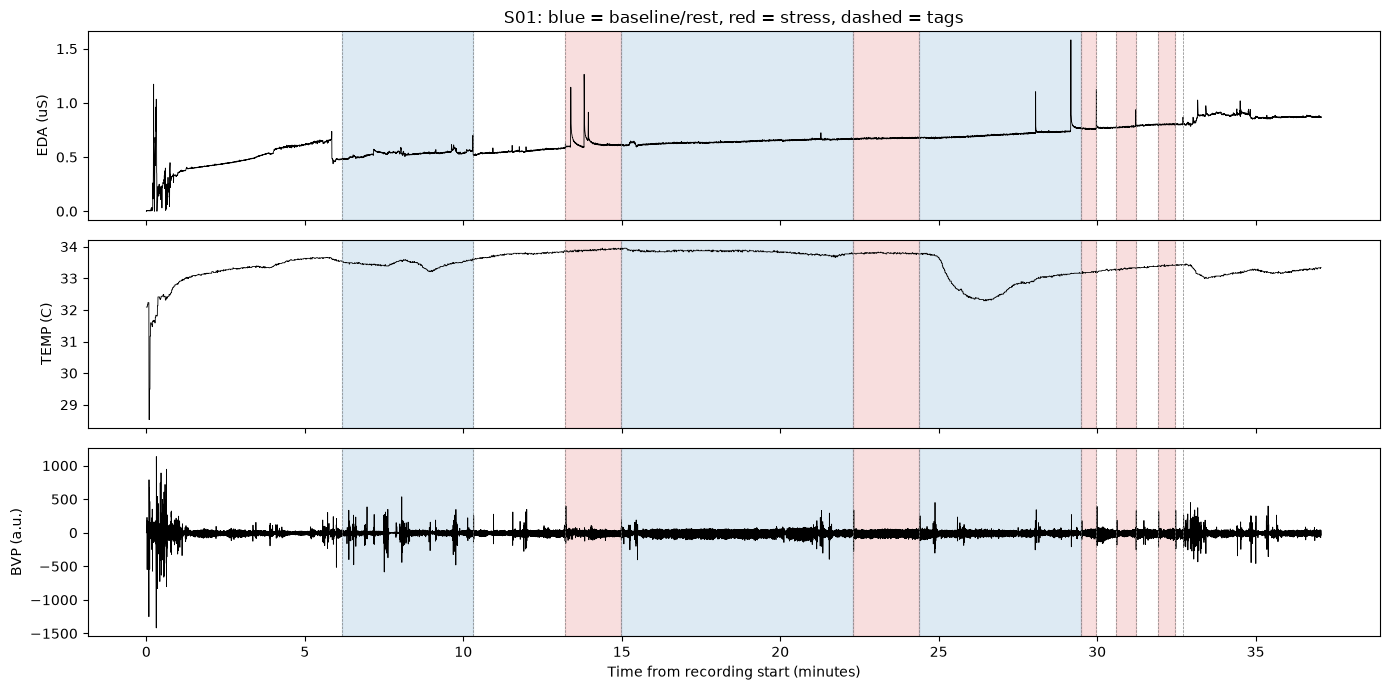

,subject_id,version,stage,condition,start_s,end_s,duration_s,complete_windows
0,S01,V1,baseline,Baseline,371.0,618.0,247.0,4
1,S01,V1,stroop,Stress,793.0,898.0,105.0,1
2,S01,V1,rest1,Baseline,898.0,1338.0,440.0,7
3,S01,V1,tmct,Stress,1338.0,1463.0,125.0,2
4,S01,V1,rest2,Baseline,1463.0,1770.0,307.0,5
5,S01,V1,real_opinion,Stress,1770.0,1798.0,28.0,0
6,S01,V1,opposite_opinion,Stress,1836.0,1873.0,37.0,0
7,S01,V1,subtraction,Stress,1915.0,1947.0,32.0,0


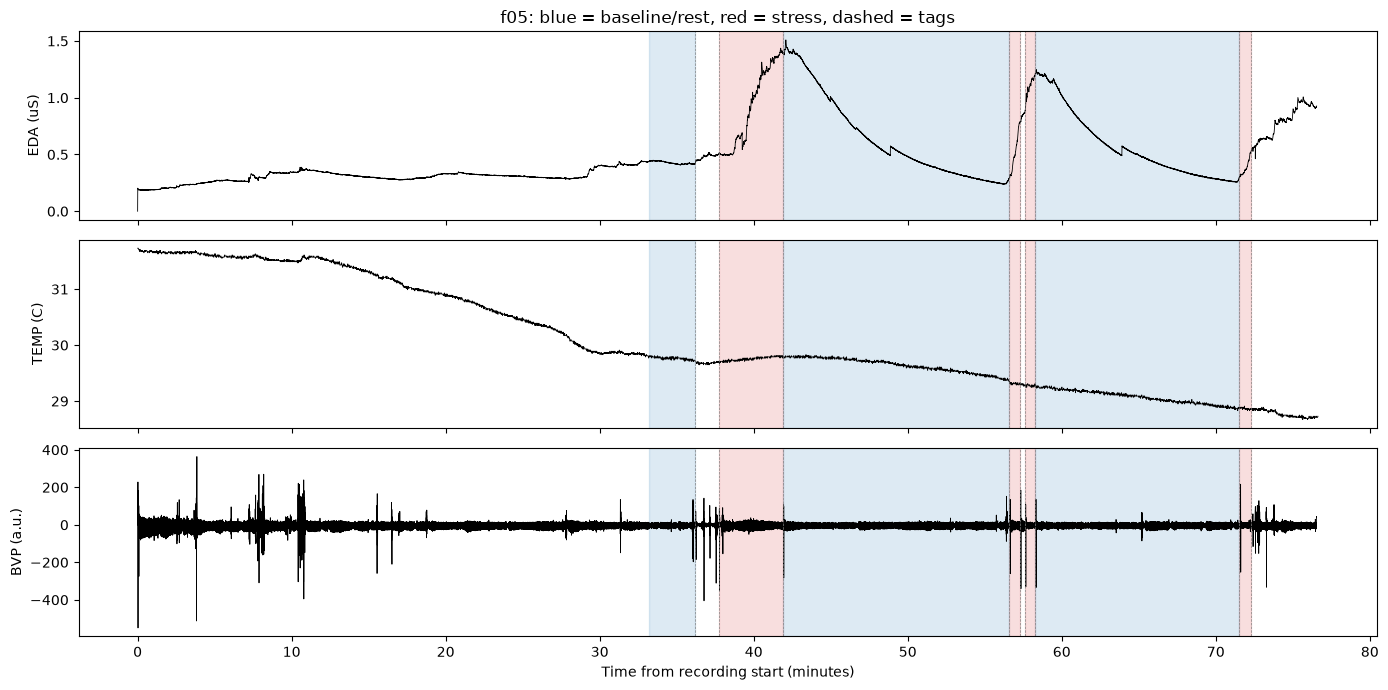

,subject_id,version,stage,condition,start_s,end_s,duration_s,complete_windows
0,f05,V2,baseline,Baseline,1992.0,2172.0,180.0,3
1,f05,V2,tmct,Stress,2263.0,2513.0,250.0,4
2,f05,V2,rest1,Baseline,2513.0,3394.0,881.0,14
3,f05,V2,real_opinion,Stress,3394.0,3436.0,42.0,0
4,f05,V2,opposite_opinion,Stress,3455.0,3495.0,40.0,0
5,f05,V2,rest2,Baseline,3495.0,4290.0,795.0,13
6,f05,V2,subtraction,Stress,4290.0,4338.0,48.0,0


In [60]:
import matplotlib.pyplot as plt

STAGE_COLORS = {"Baseline": "tab:blue", "Stress": "tab:red"}


def plot_subject_stages(subject_id):
    signals, tags = load_physionet_subject(subject_id)
    stages = build_stage_table(subject_id, signals, tags)
    reference = signals["EDA"]["start"]

    fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)

    for ax, name, ylabel in zip(
        axes, ["EDA", "TEMP", "BVP"], ["EDA (uS)", "TEMP (C)", "BVP (a.u.)"]
    ):
        sig = signals[name]
        offset = (sig["start"] - reference).total_seconds()
        t_min = (offset + np.arange(len(sig["data"])) / sig["fs"]) / 60
        ax.plot(t_min, sig["data"], color="black", linewidth=0.6)
        ax.set_ylabel(ylabel)

        for _, row in stages.iterrows():
            ax.axvspan(
                row["start_s"] / 60, row["end_s"] / 60,
                color=STAGE_COLORS[row["condition"]], alpha=0.15,
            )

    for t in tags:
        for ax in axes:
            ax.axvline((t - reference).total_seconds() / 60,
                       color="gray", linewidth=0.5, linestyle="--")

    axes[0].set_title(f"{subject_id}: blue = baseline/rest, red = stress, dashed = tags")
    axes[-1].set_xlabel("Time from recording start (minutes)")
    plt.tight_layout()
    plt.show()

    return stages


for subject_id in ["S01", "f05"]:
    stages = plot_subject_stages(subject_id)
    display(stages.round(1))

## 5. Check all subjects

In [61]:
tag_rows = []

for subject_id in list_stress_subjects():
    try:
        tags = read_tags(PHYSIONET_STRESS_DIR / subject_id / "tags.csv")
        n_tags = len(tags)
    except FileNotFoundError:
        n_tags = None

    version = protocol_version(subject_id)
    n_dropped = len(TAG_DROP.get(subject_id, []))

    tag_rows.append({
        "subject_id": subject_id,
        "version": version,
        "n_tags": n_tags,
        "expected": EXPECTED_TAGS[version],
        "tags_after_drop": None if n_tags is None else n_tags - n_dropped,
        "excluded": EXCLUDED_SUBJECTS.get(subject_id, ""),
    })

tag_check_df = pd.DataFrame(tag_rows)
tag_check_df["needs_review"] = (
    (tag_check_df["tags_after_drop"] != tag_check_df["expected"])
    & (tag_check_df["excluded"] == "")
)

display(tag_check_df)
print("Subjects to review by eye:",
      tag_check_df.loc[tag_check_df["needs_review"], "subject_id"].tolist())

,subject_id,version,n_tags,expected,tags_after_drop,excluded,needs_review
0,S01,V1,13,13,13,,False
1,S02,V1,13,13,13,duplicated data,False
2,S03,V1,13,13,13,,False
3,S04,V1,13,13,13,,False
4,S05,V1,13,13,13,,False
5,S06,V1,13,13,13,,False
6,S07,V1,13,13,13,,False
7,S08,V1,13,13,13,,False
8,S09,V1,13,13,13,,False
9,S10,V1,13,13,13,,False


Subjects to review by eye: []


## 6. Windowing and feature extraction

In [62]:
def process_physionet_subject(subject_id):
    signals, tags = load_physionet_subject(subject_id)
    stages = build_stage_table(subject_id, signals, tags)
    reference = signals["EDA"]["start"]

    feature_rows, quality_rows = [], []

    for _, stage in stages.iterrows():
        for window_number in range(stage["complete_windows"]):
            win_start_s = stage["start_s"] + window_number * WINDOW_SECONDS
            win_end_s = win_start_s + WINDOW_SECONDS
            window_id = f"{subject_id}_{stage['stage']}_win{window_number + 1:02d}"

            chunks = {}
            for name, sig in signals.items():
                fs = sig["fs"]
                offset_s = (sig["start"] - reference).total_seconds()
                start_idx = int(round((win_start_s - offset_s) * fs))
                end_idx = start_idx + WINDOW_SECONDS * fs

                if start_idx < 0 or end_idx > len(sig["data"]):
                    raise ValueError(f"{window_id}: insufficient {name} coverage.")

                chunks[name] = sig["data"][start_idx:end_idx]

            features, quality = extract_window_features(chunks)

            is_calibration = (
                stage["stage"] == "baseline"
                and window_number < CALIBRATION_WINDOWS
            )

            metadata = {
                "subject_id": subject_id,
                "version": stage["version"],
                "window_id": window_id,
                "stage": stage["stage"],
                "condition": stage["condition"],
                "y": int(stage["condition"] == "Stress"),
                "start_s": win_start_s,
                "end_s": win_end_s,
                "calibration_2min": is_calibration,
                "nonfinite_values": sum(
                    int(np.count_nonzero(~np.isfinite(c))) for c in chunks.values()
                ),
            }

            feature_rows.append({**metadata, **features})
            quality_rows.append({
                "subject_id": subject_id,
                "window_id": window_id,
                **quality,
            })

    return pd.DataFrame(feature_rows), pd.DataFrame(quality_rows), stages

In [63]:
import gc

all_features, all_quality, all_stages, processing_log = [], [], [], []

for subject_id in list_stress_subjects():
    if subject_id in EXCLUDED_SUBJECTS:
        processing_log.append({"subject_id": subject_id, "status": "excluded",
                               "reason": EXCLUDED_SUBJECTS[subject_id]})
        continue

    try:
        features_df, quality_df, stages_df = process_physionet_subject(subject_id)
    except (ValueError, FileNotFoundError) as error:
        processing_log.append({"subject_id": subject_id, "status": "failed",
                               "reason": str(error)})
        print(f"{subject_id}: FAILED - {error}")
        continue

    all_features.append(features_df)
    all_quality.append(quality_df)
    all_stages.append(stages_df)

    counts = features_df.loc[~features_df["calibration_2min"], "condition"].value_counts()
    processing_log.append({
        "subject_id": subject_id,
        "status": "processed",
        "reason": "",
        "calibration_windows": int(features_df["calibration_2min"].sum()),
        "baseline_windows": int(counts.get("Baseline", 0)),
        "stress_windows": int(counts.get("Stress", 0)),
    })
    print(f"{subject_id}: baseline = {counts.get('Baseline', 0)} | "
          f"stress = {counts.get('Stress', 0)}")
    gc.collect()

ext_features_df = pd.concat(all_features, ignore_index=True)
ext_quality_df = pd.concat(all_quality, ignore_index=True)
ext_stages_df = pd.concat(all_stages, ignore_index=True)
processing_log_df = pd.DataFrame(processing_log)

assert ext_features_df["window_id"].is_unique

ext_features_df.to_csv(OUTPUT_DIR / "external_candidate_features.csv", index=False)
ext_quality_df.to_csv(OUTPUT_DIR / "external_quality.csv", index=False)
ext_stages_df.to_csv(OUTPUT_DIR / "external_stages.csv", index=False)
processing_log_df.to_csv(OUTPUT_DIR / "external_processing_log.csv", index=False)

display(processing_log_df)

S01: baseline = 14 | stress = 3
S03: baseline = 9 | stress = 3
S04: baseline = 12 | stress = 3
S05: baseline = 9 | stress = 3
S06: baseline = 11 | stress = 4
S07: baseline = 8 | stress = 3


/Users/chengxuning/Data Science/WESAD_wearable_stress/.venv/lib/python3.13/site-packages/neurokit2/eda/eda_peaks.py:122: RuntimeWarning: All-NaN slice encountered
  valid_peaks = np.logical_and(info["SCR_Peaks"] > np.nanmin(info["SCR_Onsets"]), ~np.isnan(info["SCR_Onsets"]))  # pylint: disable=E1111


S08: baseline = 8 | stress = 3
S09: baseline = 9 | stress = 3
S10: baseline = 13 | stress = 3
S11: baseline = 8 | stress = 4
S12: baseline = 11 | stress = 3
S13: baseline = 11 | stress = 3
S14: baseline = 11 | stress = 3
S15: baseline = 11 | stress = 3
S16: baseline = 9 | stress = 3
S17: baseline = 9 | stress = 3
S18: baseline = 11 | stress = 3
f01: baseline = 34 | stress = 7
f02: baseline = 21 | stress = 6
f03: baseline = 34 | stress = 4
f04: baseline = 28 | stress = 4
f05: baseline = 28 | stress = 4
f06: baseline = 29 | stress = 4
f08: baseline = 26 | stress = 4
f09: baseline = 27 | stress = 4
f10: baseline = 28 | stress = 4
f11: baseline = 27 | stress = 4
f12: baseline = 28 | stress = 4
f13: baseline = 32 | stress = 3
f15: baseline = 24 | stress = 5
f16: baseline = 26 | stress = 4
f17: baseline = 27 | stress = 4
f18: baseline = 23 | stress = 3


,subject_id,status,reason,calibration_windows,baseline_windows,stress_windows
0,S01,processed,,2.0,14.0,3.0
1,S02,excluded,duplicated data,NaN,NaN,NaN
2,S03,processed,,2.0,9.0,3.0
3,S04,processed,,2.0,12.0,3.0
4,S05,processed,,2.0,9.0,3.0
5,S06,processed,,2.0,11.0,4.0
6,S07,processed,,2.0,8.0,3.0
7,S08,processed,,2.0,8.0,3.0
8,S09,processed,,2.0,9.0,3.0
9,S10,processed,,2.0,13.0,3.0


In [64]:
print("Windows per stage, all processed subjects:")
display(
    ext_features_df.groupby(["version", "stage"]).size().unstack(fill_value=0)
)

print("BVP detection status:")
print(ext_quality_df["bvp_detection_status"].value_counts(dropna=False))
print("\nEDA SCR status:")
print(ext_quality_df["eda_scr_status"].value_counts(dropna=False))
print("\nMissing feature values:")
print(ext_features_df[FEATURE_COLUMNS].isna().sum().loc[lambda s: s > 0])

Windows per stage, all processed subjects:


stage,baseline,rest1,rest2,stroop,subtraction,tmct
version,,,,,,
V1,48,82,78,19,0,34
V2,48,225,201,0,1,67


BVP detection status:
bvp_detection_status
completed    803
Name: count, dtype: int64

EDA SCR status:
eda_scr_status
completed                624
incomplete_amplitudes    179
Name: count, dtype: int64

Missing feature values:
EDA_scr_amplitude_mean    1
dtype: int64


In [65]:
ext_stages_df.pivot(index="subject_id", columns="stage", values="duration_s")

stage,baseline,opposite_opinion,real_opinion,rest1,rest2,stroop,subtraction,tmct
subject_id,,,,,,,,
S01,247.0,37.0,28.0,440.0,307.0,105.0,32.0,125.0
S03,187.0,31.0,34.0,256.0,295.0,104.0,33.0,128.0
S04,180.0,32.0,32.0,374.0,344.0,96.0,32.0,137.0
S05,183.0,31.0,34.0,336.0,227.0,112.0,32.0,169.0
S06,193.0,28.0,32.0,334.0,305.0,128.0,34.0,140.0
S07,163.0,32.0,32.0,272.0,285.0,103.0,31.0,129.0
S08,176.0,33.0,32.0,289.0,268.0,105.0,32.0,155.0
S09,192.0,32.0,32.0,242.0,278.0,99.0,31.0,131.0
S10,184.0,29.0,29.0,362.0,369.0,117.0,31.0,135.0


The mental arithmetic task in Version 2 lasted approximately twice as long as in Version 1: typically 4–5 minutes, compared with 2–2.5 minutes in Version 1. As a result, each Version 2 participant contributed more stress windows.

## 7. Personal calibration

In [66]:
calibration_counts = (
    ext_features_df.groupby("subject_id")["calibration_2min"].sum()
)
class_counts = (
    ext_features_df.loc[~ext_features_df["calibration_2min"]]
    .groupby("subject_id")["y"].agg(["min", "max", "count"])
)

eligible = calibration_counts.index[
    (calibration_counts == CALIBRATION_WINDOWS)
    & (class_counts["min"] == 0)
    & (class_counts["max"] == 1)
].tolist()

not_eligible = sorted(set(ext_features_df["subject_id"]) - set(eligible))
print(f"Eligible external subjects: {len(eligible)}")
print(f"Left out (short baseline or one class only): {not_eligible}")

ext_eval_df = ext_features_df.loc[ext_features_df["subject_id"].isin(eligible)].copy()

ext_reference = (
    ext_eval_df.loc[ext_eval_df["calibration_2min"]]
    .groupby("subject_id")[FEATURE_COLUMNS]
    .mean()
)

ext_uncalibrated_df = (
    ext_eval_df.loc[~ext_eval_df["calibration_2min"]].copy().reset_index(drop=True)
)

ext_calibrated_df = ext_uncalibrated_df.copy()
ext_calibrated_df[FEATURE_COLUMNS] = (
    ext_uncalibrated_df[FEATURE_COLUMNS].to_numpy(dtype=float)
    - ext_reference.loc[
        ext_uncalibrated_df["subject_id"].to_numpy(), FEATURE_COLUMNS
    ].to_numpy(dtype=float)
)

assert ext_uncalibrated_df["window_id"].equals(ext_calibrated_df["window_id"])

ext_uncalibrated_df.to_csv(OUTPUT_DIR / "external_classification_uncalibrated.csv", index=False)
ext_calibrated_df.to_csv(OUTPUT_DIR / "external_classification_calibrated_2min.csv", index=False)

display(
    ext_uncalibrated_df.groupby(["subject_id", "condition"]).size().unstack(fill_value=0)
)

Eligible external subjects: 33
Left out (short baseline or one class only): []


condition,Baseline,Stress
subject_id,,
S01,14,3
S03,9,3
S04,12,3
S05,9,3
S06,11,4
S07,8,3
S08,8,3
S09,9,3
S10,13,3


## 8. Train final models on all WESAD subjects and test on PhysioNet

In [67]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix,
)

RANDOM_STATE = 42

models = {
    "DT": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "LDA": LinearDiscriminantAnalysis(),
    "RF": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}


def make_model_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", clone(estimator)),
    ])

In [68]:
wesad_datasets = {
    "Uncalibrated": pd.read_csv(WESAD_OUTPUT_DIR / "/Users/chengxuning/Data Science/WESAD_wearable_stress/classification_uncalibrated.csv"),
    "Calibrated_2min": pd.read_csv(WESAD_OUTPUT_DIR / "/Users/chengxuning/Data Science/WESAD_wearable_stress/classification_calibrated_2min.csv"),
}
external_datasets = {
    "Uncalibrated": ext_uncalibrated_df,
    "Calibrated_2min": ext_calibrated_df,
}

for name, df in wesad_datasets.items():
    assert len(df) == 415, f"{name}: expected 415 WESAD windows, found {len(df)}"
    assert df["subject_id"].nunique() == 15
    assert set(FEATURE_COLUMNS) <= set(df.columns)

print("WESAD training tables loaded: 415 windows, 15 subjects.")

WESAD training tables loaded: 415 windows, 15 subjects.


In [69]:
def train_and_test_external(feature_columns, configuration, model_dict=models):
    """Fit on all WESAD windows, predict every external window."""
    train_df = wesad_datasets[configuration]
    test_df = external_datasets[configuration]

    X_train = train_df[feature_columns].astype(float).replace([np.inf, -np.inf], np.nan)
    y_train = train_df["y"].astype(int)
    X_test = test_df[feature_columns].astype(float).replace([np.inf, -np.inf], np.nan)

    prediction_tables = []

    for model_name, estimator in model_dict.items():
        pipeline = make_model_pipeline(estimator)
        pipeline.fit(X_train, y_train)

        prediction_tables.append(pd.DataFrame({
            "configuration": configuration,
            "model": model_name,
            "subject_id": test_df["subject_id"].to_numpy(),
            "version": test_df["version"].to_numpy(),
            "window_id": test_df["window_id"].to_numpy(),
            "stage": test_df["stage"].to_numpy(),
            "y": test_df["y"].to_numpy(),
            "y_pred": pipeline.predict(X_test),
            "p_stress": pipeline.predict_proba(X_test)[:, 1],
        }))

    return pd.concat(prediction_tables, ignore_index=True)


def score_block(y, y_pred):
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
    return {
        "balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "stress_f1": f1_score(y, y_pred, pos_label=1, zero_division=0),
        "stress_recall": recall_score(y, y_pred, pos_label=1, zero_division=0),
        "n_baseline": int(tn + fp),
        "n_stress": int(fn + tp),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def per_subject_scores(predictions):
    rows = []
    for keys, group in predictions.groupby(["configuration", "model", "subject_id", "version"]):
        rows.append(dict(zip(["configuration", "model", "subject_id", "version"], keys))
                    | score_block(group["y"], group["y_pred"]))
    return pd.DataFrame(rows)


def pooled_scores(predictions, by=("configuration", "model")):
    rows = []
    for keys, group in predictions.groupby(list(by)):
        rows.append(dict(zip(by, keys)) | score_block(group["y"], group["y_pred"]))
    return pd.DataFrame(rows)

In [70]:
external_predictions_df = pd.concat(
    [train_and_test_external(FEATURE_COLUMNS, config) for config in external_datasets],
    ignore_index=True,
)
external_subject_scores_df = per_subject_scores(external_predictions_df)

external_predictions_df.to_csv(OUTPUT_DIR / "external_predictions.csv", index=False)
external_subject_scores_df.to_csv(OUTPUT_DIR / "external_subject_scores.csv", index=False)

print(f"Predicted {external_predictions_df['window_id'].nunique()} external windows "
      f"from {external_predictions_df['subject_id'].nunique()} subjects.")

Predicted 737 external windows from 33 subjects.


## 9. Results

Three views:
1. **Per subject**, mean ± SD across external subjects. Comparable with WESAD LOSO.
2. **Pooled**, all external windows together. More stable when each subject has few stress windows.
3. **By protocol version**, pooled within V1 and within V2.

In [71]:
METRICS = ["balanced_accuracy", "stress_f1", "stress_recall"]

per_subject_summary = (
    external_subject_scores_df
    .groupby(["configuration", "model"], sort=False)[METRICS]
    .agg(["mean", "std"])
)
per_subject_summary.columns = [f"{m}_{s}" for m, s in per_subject_summary.columns]
per_subject_summary.insert(
    0, "n_subjects",
    external_subject_scores_df.groupby(["configuration", "model"], sort=False)["subject_id"].nunique(),
)

pooled_summary = pooled_scores(external_predictions_df)
version_summary = pooled_scores(external_predictions_df, by=("configuration", "model", "version"))

per_subject_summary.to_csv(OUTPUT_DIR / "external_summary_per_subject.csv")
pooled_summary.to_csv(OUTPUT_DIR / "external_summary_pooled.csv", index=False)
version_summary.to_csv(OUTPUT_DIR / "external_summary_by_version.csv", index=False)

print("1. Per-subject mean and SD:")
display(per_subject_summary.round(3))
print("2. Pooled over all external windows:")
display(pooled_summary.round(3))
print("3. Pooled within each protocol version:")
display(version_summary.round(3))

1. Per-subject mean and SD:


n_subjects  balanced_accuracy_mean  \
configuration   model                                       
Calibrated_2min DT             33                   0.549   
                LDA            33                   0.632   
                RF             33                   0.509   
Uncalibrated    DT             33                   0.607   
                LDA            33                   0.650   
                RF             33                   0.622   

                       balanced_accuracy_std  stress_f1_mean  stress_f1_std  \
configuration   model                                                         
Calibrated_2min DT                     0.156           0.354          0.194   
                LDA                    0.165           0.323          0.324   
                RF                     0.203           0.320          0.232   
Uncalibrated    DT                     0.121           0.352          0.188   
                LDA                    0.160           0.355          0.279   
                RF                     0.159           0.271          0.290   

                       stress_recall_mean  stress_recall_std  
configuration   model                                         
Calibrated_2min DT                  0.731              0.301  
                LDA                 0.373              0.385  
                RF                  0.690              0.392  
Uncalibrated    DT                  0.630              0.376  
                LDA                 0.487              0.418  
                RF                  0.402              0.445

2. Pooled over all external windows:


,configuration,model,balanced_accuracy,stress_f1,stress_recall,n_baseline,n_stress,tn,fp,fn,tp
0,Calibrated_2min,DT,0.555,0.300,0.744,616,121,226,390,31,90
1,Calibrated_2min,LDA,0.626,0.375,0.372,616,121,542,74,76,45
2,Calibrated_2min,RF,0.518,0.276,0.702,616,121,206,410,36,85
3,Uncalibrated,DT,0.620,0.348,0.636,616,121,372,244,44,77
4,Uncalibrated,LDA,0.653,0.409,0.463,616,121,519,97,65,56
5,Uncalibrated,RF,0.636,0.389,0.405,616,121,534,82,72,49


3. Pooled within each protocol version:


,configuration,model,version,balanced_accuracy,stress_f1,stress_recall,n_baseline,n_stress,tn,fp,fn,tp
0,Calibrated_2min,DT,V1,0.538,0.379,0.755,174,53,56,118,13,40
1,Calibrated_2min,DT,V2,0.560,0.256,0.735,442,68,170,272,18,50
2,Calibrated_2min,LDA,V1,0.667,0.494,0.415,174,53,160,14,31,22
3,Calibrated_2min,LDA,V2,0.601,0.305,0.338,442,68,382,60,45,23
4,Calibrated_2min,RF,V1,0.528,0.374,0.774,174,53,49,125,12,41
5,Calibrated_2min,RF,V2,0.501,0.222,0.647,442,68,157,285,24,44
6,Uncalibrated,DT,V1,0.619,0.435,0.698,174,53,94,80,16,37
7,Uncalibrated,DT,V2,0.609,0.294,0.588,442,68,278,164,28,40
8,Uncalibrated,LDA,V1,0.685,0.508,0.623,174,53,130,44,20,33
9,Uncalibrated,LDA,V2,0.609,0.319,0.338,442,68,389,53,45,23


In [72]:
# Side-by-side with the WESAD LOSO means reported in the Results section.
wesad_loso_ba = pd.DataFrame({
    "configuration": ["Uncalibrated"] * 3 + ["Calibrated_2min"] * 3,
    "model": ["DT", "LDA", "RF"] * 2,
    "WESAD_LOSO_BA": [0.820, 0.917, 0.886, 0.935, 0.913, 0.933],
})

comparison_df = (
    wesad_loso_ba
    .merge(per_subject_summary["balanced_accuracy_mean"].rename("External_BA_per_subject").reset_index(),
           on=["configuration", "model"])
    .merge(pooled_summary[["configuration", "model", "balanced_accuracy"]]
           .rename(columns={"balanced_accuracy": "External_BA_pooled"}),
           on=["configuration", "model"])
)
comparison_df["Drop_pp_per_subject"] = 100 * (
    comparison_df["WESAD_LOSO_BA"] - comparison_df["External_BA_per_subject"]
)

comparison_df.to_csv(OUTPUT_DIR / "external_vs_wesad.csv", index=False)
display(comparison_df.round(3))

,configuration,model,WESAD_LOSO_BA,External_BA_per_subject,External_BA_pooled,Drop_pp_per_subject
0,Uncalibrated,DT,0.820,0.607,0.620,21.269
1,Uncalibrated,LDA,0.917,0.650,0.653,26.739
2,Uncalibrated,RF,0.886,0.622,0.636,26.448
3,Calibrated_2min,DT,0.935,0.549,0.555,38.635
4,Calibrated_2min,LDA,0.913,0.632,0.626,28.061
5,Calibrated_2min,RF,0.933,0.509,0.518,42.386


In [73]:
# Effect of calibration on each external subject.
calibration_pairs = (
    external_subject_scores_df
    .pivot_table(index=["model", "subject_id"], columns="configuration",
                 values="balanced_accuracy")
    .reset_index()
)
calibration_pairs["change_pp"] = 100 * (
    calibration_pairs["Calibrated_2min"] - calibration_pairs["Uncalibrated"]
)

tol = 1e-8
calibration_change_summary = calibration_pairs.groupby("model").agg(
    mean_change_pp=("change_pp", "mean"),
    median_change_pp=("change_pp", "median"),
    improved=("change_pp", lambda s: int((s > tol).sum())),
    unchanged=("change_pp", lambda s: int((s.abs() <= tol).sum())),
    worsened=("change_pp", lambda s: int((s < -tol).sum())),
)

calibration_pairs.to_csv(OUTPUT_DIR / "external_calibration_pairs.csv", index=False)
display(calibration_change_summary.round(2))

,mean_change_pp,median_change_pp,improved,unchanged,worsened
model,,,,,
DT,-5.87,-5.56,12,2,19
LDA,-1.72,0.00,16,4,13
RF,-11.24,-10.42,8,2,23


In [74]:
# Which stages are misclassified? Useful for the Discussion.
stage_error_df = (
    external_predictions_df
    .assign(correct=lambda d: d["y"] == d["y_pred"])
    .groupby(["configuration", "model", "version", "stage"])["correct"]
    .agg(n_windows="size", accuracy="mean")
    .reset_index()
)
stage_error_df.to_csv(OUTPUT_DIR / "external_accuracy_by_stage.csv", index=False)
display(
    stage_error_df.loc[stage_error_df["configuration"] == "Calibrated_2min"]
    .pivot_table(index=["version", "stage"], columns="model", values="accuracy")
    .round(3)
)

model                   DT    LDA     RF
version stage                           
V1      baseline     0.500  1.000  0.500
        rest1        0.280  0.927  0.244
        rest2        0.333  0.897  0.282
        stroop       0.895  0.421  0.895
        tmct         0.676  0.412  0.706
V2      baseline     0.812  0.938  0.750
        rest1        0.356  0.853  0.329
        rest2        0.383  0.871  0.353
        subtraction  1.000  0.000  1.000
        tmct         0.731  0.343  0.642

In [75]:
rest_position = (
    external_predictions_df
    .query("configuration == 'Calibrated_2min' and stage in ['rest1', 'rest2']")
    .assign(
        window_number=lambda d: d["window_id"].str.extract(r"win(\d+)$")[0].astype(int).clip(upper=10),
        correct=lambda d: d["y"] == d["y_pred"],
    )
)

display(
    rest_position
    .pivot_table(index="window_number", columns="model", values="correct", aggfunc="mean")
    .round(2)
)

model,DT,LDA,RF
window_number,,,
1,0.27,0.82,0.21
2,0.32,0.92,0.24
3,0.30,0.92,0.29
4,0.33,0.91,0.31
5,0.35,0.85,0.33
6,0.35,0.89,0.32
7,0.39,0.76,0.33
8,0.39,0.87,0.32
9,0.48,0.87,0.42


## 10. RQ2 on external data: signal removal

In [76]:
SIGNAL_NAMES = ["BVP", "EDA", "TEMP", "ACC"]

ablation_sets = {"Full": FEATURE_COLUMNS} | {
    f"Without_{signal}": [f for f in FEATURE_COLUMNS if not f.startswith(f"{signal}_")]
    for signal in SIGNAL_NAMES
}

ablation_tables = []
for set_name, columns in ablation_sets.items():
    preds = train_and_test_external(columns, "Calibrated_2min")
    preds["feature_set"] = set_name
    ablation_tables.append(preds)

external_ablation_predictions = pd.concat(ablation_tables, ignore_index=True)

ext_ablation_subject = []
for set_name, group in external_ablation_predictions.groupby("feature_set"):
    scores = per_subject_scores(group)
    scores["feature_set"] = set_name
    ext_ablation_subject.append(scores)
ext_ablation_subject = pd.concat(ext_ablation_subject, ignore_index=True)

ext_ablation_pooled = pooled_scores(external_ablation_predictions, by=("feature_set", "model"))

ablation_order = list(ablation_sets)
print("Mean per-subject balanced accuracy on PhysioNet:")
display(
    ext_ablation_subject.pivot_table(index="feature_set", columns="model",
                                     values="balanced_accuracy", aggfunc="mean")
    .reindex(ablation_order).round(3)
)
print("Pooled balanced accuracy on PhysioNet:")
display(
    ext_ablation_pooled.pivot_table(index="feature_set", columns="model",
                                    values="balanced_accuracy")
    .reindex(ablation_order).round(3)
)

external_ablation_predictions.to_csv(OUTPUT_DIR / "external_ablation_predictions.csv", index=False)
ext_ablation_subject.to_csv(OUTPUT_DIR / "external_ablation_subject_scores.csv", index=False)
ext_ablation_pooled.to_csv(OUTPUT_DIR / "external_ablation_pooled.csv", index=False)

Mean per-subject balanced accuracy on PhysioNet:


model,DT,LDA,RF
feature_set,,,
Full,0.549,0.632,0.509
Without_BVP,0.508,0.592,0.516
Without_EDA,0.528,0.564,0.491
Without_TEMP,0.611,0.621,0.568
Without_ACC,0.545,0.598,0.521


Pooled balanced accuracy on PhysioNet:


model,DT,LDA,RF
feature_set,,,
Full,0.555,0.626,0.518
Without_BVP,0.517,0.592,0.522
Without_EDA,0.512,0.550,0.472
Without_TEMP,0.628,0.618,0.589
Without_ACC,0.551,0.590,0.530


In [77]:
# Drop after removing each signal, in percentage points (per-subject means).
full = (ext_ablation_subject.loc[ext_ablation_subject["feature_set"] == "Full"]
        .set_index(["model", "subject_id"])["balanced_accuracy"])

drop_rows = []
for signal in SIGNAL_NAMES:
    reduced = (ext_ablation_subject.loc[ext_ablation_subject["feature_set"] == f"Without_{signal}"]
               .set_index(["model", "subject_id"])["balanced_accuracy"])
    drop = 100 * (full - reduced)
    for model, values in drop.groupby(level="model"):
        drop_rows.append({"removed_signal": signal, "model": model,
                          "mean_drop_pp": values.mean(),
                          "n_hurt": int((values > 1e-8).sum()),
                          "n_unchanged": int((values.abs() <= 1e-8).sum()),
                          "n_helped": int((values < -1e-8).sum())})

external_ablation_drop = pd.DataFrame(drop_rows)
external_ablation_drop.to_csv(OUTPUT_DIR / "external_ablation_drop.csv", index=False)

display(
    external_ablation_drop.pivot(index="removed_signal", columns="model", values="mean_drop_pp")
    .reindex(SIGNAL_NAMES).round(2)
)

model,DT,LDA,RF
removed_signal,,,
BVP,4.08,4.03,-0.69
EDA,2.02,6.88,1.82
TEMP,-6.27,1.18,-5.86
ACC,0.38,3.42,-1.21
